# Prefix-cached ACDC on standardized MIB IOI

Independent implementation of the computational optimization described in the supplied research log, Stage J. Its reported **2.35×** speedup used auto-circuit IOI and squared probability distance; the original implementation and trace are unavailable here. Our MIB adaptation uses the official negative IOI logit difference and a documented compatible exact edge-pruning traversal. It is not an exact numerical reproduction of that independent configuration.

The corrected dynamic sender semantics are retained: donor minus **current intervened sender**. No sketching, Hessians, group deletion or MAttr methods are used. Previous experiments and installed environments are preserved.

In [1]:
from pathlib import Path
from datetime import datetime, timezone
import os, json, subprocess
import pandas as pd
from IPython.display import display, Image, Markdown
ROOT=next(p for p in [Path.cwd().resolve(),*Path.cwd().resolve().parents] if (p/'src/acdc_prefix_cache').is_dir())
campaigns=sorted((ROOT/'results/acdc_prefix_cache').glob('*')) if (ROOT/'results/acdc_prefix_cache').exists() else []
RESULTS=Path('H:\\GenAI Research\\sketch_prune\\results\\acdc_prefix_cache\\20261019T173713Z')
RUN_STAGE_A=False
RUN_STAGE_B=False
RUN_STAGE_C=False
ALLOW_FULL_GRAPH=False
print('Campaign:',RESULTS)
print('Defaults: GPT-2 Small, official MIB IOI, float32, train 16, validation 16, batch 2, seed 42, threshold 0.05.')

def linux_path(path):
    path=Path(path).resolve()
    return '/mnt/'+path.drive[0].lower()+path.as_posix()[2:] if os.name=='nt' else str(path)

def run(stage):
    argv=['bash',linux_path(ROOT/'src/acdc_prefix_cache/run_wsl.sh'),'--stage',stage,'--out',linux_path(RESULTS)]
    if stage=='c':
        assert ALLOW_FULL_GRAPH, 'Stage C requires explicit full-graph authorization; it can run for hours.'
        argv+=['--allow-full-graph']
    if os.name=='nt':argv=['wsl','-d','Ubuntu','--']+argv
    print('Running:',argv)
    subprocess.run(argv,cwd=ROOT,check=True)

Campaign: H:\GenAI Research\sketch_prune\results\acdc_prefix_cache\20261019T173713Z
Defaults: GPT-2 Small, official MIB IOI, float32, train 16, validation 16, batch 2, seed 42, threshold 0.05.


## Stage A — correctness

The standard executor runs the complete transformer. The cached executor checks the descendant closure of **all** removed receivers against every skipped prefix sender, restores a clean residual boundary, seeds only proven-unaffected current senders, and executes the remaining native blocks. An earlier accepted deletion moves the start boundary earlier, even for a late candidate. Final residual/logit receivers conservatively retain the final block. Cache buffers are cloned before possible modification.

Stage A runs ten real small-TransformerLens unit tests, thirty single-edge queries across layers 0/2/4/6/8/10/11, eight dependent/random multi-edge states, a 32-edge restricted reverse-topological subsequence, a longer 64-edge prefix, checkpoint interruption/rebuild/replay, and held-out final-circuit checks. Official MIB and the corrected shared adapter supply independent oracles. Actual root forwards and block executions are counted; inference uses no gradients. Stage-A timings are diagnostic only.

In [2]:
if RUN_STAGE_A: run('a')
for name in ['correctness_results','stage_a_trajectories','stage_a_validation','runtime_estimates']:
    path=RESULTS/(name+'.csv')
    if path.exists():
        print(name);display(pd.read_csv(path))
    else:print(name+': not measured')
path=RESULTS/'decision_trace_comparison.csv'
if path.exists():
    trace=pd.read_csv(path)
    print('Saved decision comparison records:',len(trace))
    display(trace.groupby('trajectory')[['decision_matches','state_before_matches','state_after_matches','exact_loss_match']].all())


correctness_results


,test,case,examples,max_absolute_error,mean_absolute_error,exact_matches,official_max_absolute_error,passed
0,single,input->a0.h0<q>,16.0,0.0,0.0,16.0,0.000000,True
1,single,input->a0.h0<k>,16.0,0.0,0.0,16.0,0.000000,True
2,single,input->a0.h0<v>,16.0,0.0,0.0,16.0,0.000000,True
3,single,a0.h0->m0,16.0,0.0,0.0,16.0,0.000000,True
4,single,m1->a2.h0<q>,16.0,0.0,0.0,16.0,0.000000,True
5,single,m1->a2.h0<k>,16.0,0.0,0.0,16.0,0.000000,True
6,single,m1->a2.h0<v>,16.0,0.0,0.0,16.0,0.000000,True
7,single,a2.h0->m2,16.0,0.0,0.0,16.0,0.000000,True
8,single,m3->a4.h0<q>,16.0,0.0,0.0,16.0,0.000000,True
9,single,m3->a4.h0<k>,16.0,0.0,0.0,16.0,0.000000,True


stage_a_trajectories


,stage,trajectory,method,candidate_checks,accepted_removals,final_edge_count,circuit_hash,search_seconds_diagnostic_only,full_graph
0,A_correctness_not_performance,restricted_32,standard,32,29,32462,1096339b459593f6bb9c0f1ce343bee00773903989b9c7...,10.648042,False
1,A_correctness_not_performance,restricted_32,cached,32,29,32462,1096339b459593f6bb9c0f1ce343bee00773903989b9c7...,6.617505,False
2,A_correctness_not_performance,partial_prefix_64,standard,64,49,32442,8b491da4a5ca8c5d001b544333a419546ea8ab706be4ef...,19.355436,False
3,A_correctness_not_performance,partial_prefix_64,cached,64,49,32442,8b491da4a5ca8c5d001b544333a419546ea8ab706be4ef...,5.474827,False


stage_a_validation


,trajectory,examples,standard_loss,cached_loss,official_loss,max_absolute_error,official_max_absolute_error,retained_identity_match
0,restricted_32,16,-2.475981,-2.475981,-2.475981,0.0,0.000013,True
1,partial_prefix_64,16,-8.159912,-8.159912,-8.159912,0.0,0.000005,True


runtime_estimates


,discovery_examples,stage_b_medium_paired_seconds_estimate,stage_c_one_paired_full_seconds_estimate,stage_c_requested_repeats_seconds_estimate,performance_measurement,method
0,16,200.797842,13365.242485,40095.727455,False,"Stage-A diagnostic query timing, linear exampl..."
1,32,401.595684,26730.484970,80191.454909,False,"Stage-A diagnostic query timing, linear exampl..."
2,64,803.191368,53460.969939,160382.909818,False,"Stage-A diagnostic query timing, linear exampl..."
3,128,1606.382737,106921.939879,320765.819637,False,"Stage-A diagnostic query timing, linear exampl..."


Saved decision comparison records: 160


,decision_matches,state_before_matches,state_after_matches,exact_loss_match
trajectory,,,,
interrupt_rebuild_resume,True,True,True,True
partial_prefix_64,True,True,True,True
restricted_32,True,True,True,True


## Stage B — performance (not automatic)

Review the Stage-A report and runtime estimates before enabling this flag. This stage repeats seven-layer microbenchmarks and matched medium partial trajectories at 16/32/64/128 discovery examples. Both arms pay their own donor construction, tokenization and baseline/cache preparation. Timing synchronizes CUDA, alternates arm order, and records power/clock telemetry, cache bytes, isolated allocator peaks, total elapsed time, and held-out loss. Warmup, micro timings, search time, setup time, and validation are separate. Partial prefixes are late-layer-heavy and cannot establish full-search speedup.

In [3]:
if RUN_STAGE_B: run('b')
for name in ['layerwise_benchmark','full_acdc_benchmark','measured_paired_speedups']:
    path=RESULTS/(name+'.csv')
    if path.exists():
        frame=pd.read_csv(path);print(name+': '+str(len(frame))+' rows');display(frame.head(24))
    else:print(name+': not run')


layerwise_benchmark: 0 rows


,stage,method,trial,earliest_affected_layer,seconds


full_acdc_benchmark: 0 rows


,stage,method,trial,discovery_examples,candidate_checks,total_seconds


measured_paired_speedups: not run


## Stage C — full graph (disabled by default)

This stage requires passing A and B, plus explicit `ALLOW_FULL_GRAPH=True` and `RUN_STAGE_C=True`. It visits all 32,491 real edges with identical seeds, dataset, loss, threshold and traversal in both arms. Checkpoints save the actual retained identities and trace; rebuilding caches and replay overhead count toward cost. Do not start this automatically. The independent log's 2.35× speedup and 686-edge circuit are not targets for a different task loss/data implementation.

stage_a_loss_agreement.png


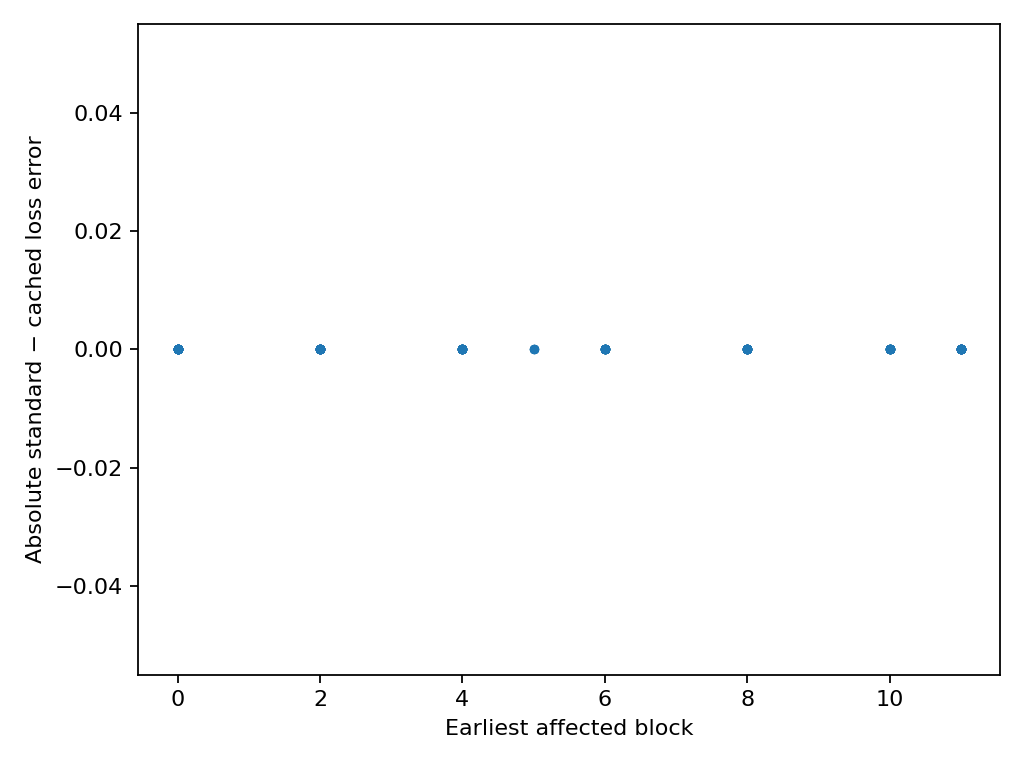

# Prefix-cached ACDC: independent MIB adaptation

Campaign: `results/acdc_prefix_cache/20261019T173713Z`.

## Scope and independent reference

The supplied Downloads/RESEARCH_LOG.md, Stage J, reports 2.35× faster execution, bitwise loss agreement and a later replay of all 32,491 decisions with the same 686-edge GPT-2 circuit. It describes auto-circuit single-template IOI, ABC donors, and squared full-vocabulary probability distance. The reported full replay took 2.5 hours under power capping. Those are independent author-reported measurements, not measurements from this repository. The complete Stage-J implementation and original trace are not supplied or present in the inspected clones; source-log identity and the relevant excerpt are saved in independent_source.json. Exact reconstruction of that original experiment has not been performed.

This implementation instead uses official MIB IOI train/validation data, GPT-2 Small, float32, and the official negative logit difference (get_metric(..., loss=True)). A deletion is accepted when proposed mean loss minus current mean loss is strictly below the fixed threshold. This signed rule matches the default ACDC abs_value_threshold=False; the historical restricted Sketch-ACDC absolute-change decision rule is not silently reused. The threshold, traversal and starting graph are identical between the two new arms. This is an optimization reproduction on MIB IOI, not a numerical reproduction of the independent 2.35× experiment.

## Implementation and safety

The standard executor always runs the full transformer. The cached executor uses TransformerLens.forward(start_at_layer=L) with a cloned full-model residual stream before block L, the original token IDs and the original padding mask. Residual connections and all attention/MLP operations within the suffix are executed by TransformerLens itself. A final-logit receiver uses the last block rather than bypassing its hook_resid_post. Block zero falls back to a full forward.

The prefix proof uses the actual full MIB DAG. Every removed edge changes its receiver; its descendant closure is propagated through all graph dependencies. Cached sender nodes before the proposed boundary must have empty intersection with that closure, and no removed receiver hook may be skipped. The union includes all previously accepted removals, not only the current candidate. Arbitrary out-of-order states therefore move the boundary earlier when necessary; explicitly unsafe boundaries are rejected. Unknown nodes, unsupported architectures, model/config changes and incompatible checkpoint identities fail rather than silently reusing stale state.

Both arms cache identical fixed corrupted donors. Only the optimized arm also retains clean sender tensors and residual boundaries. At a skipped, proven-unaffected prefix, donor-minus-clean is valid. At every sender in the suffix, donor-minus-CURRENT-intervened output is recomputed. The matrix update is checked against the corrected shared receiver_patch function, corrected EdgeExperiment on dependent real-model queries, and the independent official MIB evaluate_graph. The historical FrozenSenderEdgeExperiment is never used. No gradients are tracked during inference. Repeated intervention queries are executed, not memoized.

Traversal sorts by descending receiver DAG phase, descending sender index, then edge name. Attention and MLP have separate within-block phases. The compatible exact search tests each real edge independently and performs no automatic cascading deletions or node-skipping shortcuts. The official MIB oracle does its own graph.prune(); its losses are independently checked, including a disconnected-head case. Saved retained identities refer to the explicit tested edge mask, not a relabeled canonical graph. This traversal/control flow is not claimed to match an unavailable auto-circuit trace.

Configuration: discovery 16, validation 16, batch 2, seed 42, threshold 0.05, atol 5e-05, rtol 1e-05. Public test is not used. Existing installed WSL packages are reused without installing dependencies or importing MAttr experiment code. The older corrected MIB clone is selected explicitly; all previously tracked experiment artifacts are protected by SHA-256 checks.

## Stage A measurements

**Stage A passed.** 30 single-edge and 8 multi-edge queries cover receiver layers 0,2,4,6,8,10,11, q/k/v inputs, MLP inputs, final residual receivers, dependent senders, randomized masks, and an early previous deletion paired with a late candidate.

Across 608 per-example train comparisons: max absolute loss error **0**, mean absolute error **0**, exact matches **608/608**. Maximum meaningful relative error: 0. Maximum error against the independent official MIB oracle: **1.6212463e-05**.

The restricted trajectory checks 32 edges selected across early/middle/late layers in reverse-topological subsequence order. The longer trajectory checks the first 64 edges of the full deterministic traversal. Candidate IDs, proposed losses, keep/remove decisions, before/after state hashes, and complete retained edge lists match. Interrupting, rebuilding caches and resuming the longer trajectory also matches all 64 decisions. In total, 160 saved comparison records include the resume replay; these are not 160 unique full-graph decisions.

**No full 32,491-edge search was executed.** Matching these partial traces does not establish full-trajectory correctness or full-search speedup. Stage A uses diagnostic timings, not a repeated, isolated end-to-end performance experiment.

Ten real small-TransformerLens unit tests passed. The GPU gate recorded 3,467 actual root forward batches, 6,934 example-forwards and 26,948 actual block executions across both arms, independent oracles, warmups, replay and held-out checks. Every recorded inference forward disabled gradients.

Held-out validation checks of the two final partial circuits:

| Trajectory | Examples | Standard loss | Cached loss | Max discrepancy |
|---|---:|---:|---:|---:|
| restricted_32 | 16 | -2.4759810 | -2.4759810 | 0 |
| partial_prefix_64 | 16 | -8.1599121 | -8.1599121 | 0 |

Maximum sampled Stage-A preparation allocator peak: 1226.6 MiB allocated / 1380.0 MiB reserved. Standard donor cache: 138.9 MiB; optimized donor + clean-prefix cache: 288.4 MiB. Both executors coexist for correctness testing, so these allocator peaks are **not** isolated per-method VRAM benchmarks. Stage B measures isolated allocations.

## Planning estimates before Stage B/C

These are rough planning estimates, not measured benchmark results, speedup claims, confidence intervals, or upper bounds. They scale Stage-A diagnostic query times linearly with discovery size and interpolate missing layers from nearby measured boundaries. Growing deletion-mask bookkeeping, checkpoint I/O, validation, microbenchmark warmup, GPU clocks and caching memory pressure can change runtime substantially. Stage B is needed to calibrate them. Stage-C rows below are one standard/cached full-graph pair; repeating all sizes is potentially hours-long.

| Discovery examples | B medium pairs (configured repeats) | C one full pair | C configured repeats |
|---|---:|---:|---:|
| 16 | 3.3 min | 3.71 h | 11.14 h |
| 32 | 6.7 min | 7.43 h | 22.28 h |
| 64 | 13.4 min | 14.85 h | 44.55 h |
| 128 | 26.8 min | 29.70 h | 89.10 h |

Stage B additionally includes seven-layer repeated microbenchmarks and held-out evaluations. The first traversal prefixes are concentrated at late receivers and must be labeled partial trajectories. Their end-to-end speedup cannot be promoted to a full-search speedup.

## Performance status and next action

Stage B: NOT RUN. Stage C: NOT RUN; disabled by default. The current Stage-A report therefore does not claim a measured speedup, fastest layer, discovery-size trend, or cross-model generalization. The small real-model unit tests are structural correctness tests, not a second standardized model/task benchmark.

Next authorized checkpoint: review the implementation, numerical agreement and estimates before executing Stage B or C. No sketching, Hessians, group deletion or MAttr algorithm has been implemented. Possible later optimization: avoid conservative full-graph dependency propagation for nodes proven unable to affect logits, but that requires a separate correctness proof and is not implemented.



In [4]:
if RUN_STAGE_C: run('c')
for path in sorted(RESULTS.glob('*.png')):
    print(path.name);display(Image(filename=str(path)))
report=RESULTS/'ACDC_PREFIX_CACHE_REPORT.md'
if report.exists(): display(Markdown(report.read_text(encoding='utf-8')))
else: print('No conclusions: Stage A has not produced a report yet.')
